### 📊 Feature Explanations

- **Demographics**
  - `gender`: Male/Female. Often weak predictor — churn usually isn’t strongly tied to gender.
  - `SeniorCitizen`: Binary (0/1). Older customers may have different churn behavior.
  - `Partner`: Whether the customer has a spouse/partner. Can influence stability.
  - `Dependents`: Whether the customer has dependents. May affect service usage patterns.

- **Account Tenure & Charges**
  - `tenure`: Number of months the customer has stayed. Longer tenure usually means lower churn risk.
  - `MonthlyCharges`: Amount billed monthly. Higher charges can increase churn if perceived as expensive.
  - `TotalCharges`: Lifetime charges. Correlates with tenure and overall value.

- **Services Subscribed**
  - `PhoneService`: Whether the customer has phone service.
  - `MultipleLines`: Single line vs multiple lines.
  - `InternetService`: DSL, Fiber optic, or None. Strong predictor — internet type affects churn.
  - `OnlineSecurity`: Whether online security add-on is subscribed.
  - `OnlineBackup`: Backup service subscription.
  - `DeviceProtection`: Device protection plan.
  - `TechSupport`: Technical support availability.
  - `StreamingTV`: Streaming TV service.
  - `StreamingMovies`: Streaming movies service.

- **Contract & Billing**
  - `Contract`: Month-to-month, One year, Two year. One of the strongest predictors — month-to-month customers churn more.
  - `PaperlessBilling`: Whether billing is paperless. Sometimes linked to churn.
  - `PaymentMethod`: Electronic check, mailed check, bank transfer, credit card. Payment method can correlate with churn risk.

- **Target**
  - `Churn`: The label (Yes/No). Whether the customer left the service.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv(r'C:\Users\SARFRAJ\Desktop\ML_Nootebook\ML Project\online+retail\Telco-Customer-Churn.csv')
# df = pd.read_csv(r'Telco-Customer-Churn.csv')

In [3]:
df.head()

,Unnamed: 0,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        7043 non-null   int64  
 1   customerID        7043 non-null   str    
 2   gender            7043 non-null   str    
 3   SeniorCitizen     7043 non-null   int64  
 4   Partner           7043 non-null   str    
 5   Dependents        7043 non-null   str    
 6   tenure            7043 non-null   int64  
 7   PhoneService      7043 non-null   str    
 8   MultipleLines     7043 non-null   str    
 9   InternetService   7043 non-null   str    
 10  OnlineSecurity    7043 non-null   str    
 11  OnlineBackup      7043 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  Contract          7043 non-null   str    
 17  Paperl

#### Analysis From Info

* Dataset has total 21 columns and 7043 rows.
* 'Unnamed: 0', 'customerID' Both column is identifier or not useful so we can drop it.
* For now No missing value

<!--  -->

#### Droping ['Unnamed: 0', 'customerID'] column

In [5]:
df.drop(columns=['Unnamed: 0', 'customerID'],inplace=True)

In [6]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

<!--  -->

#### Checking Null Value and Duplicate value

In [7]:
df.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(22)

In [9]:
df.drop_duplicates(inplace=True)

#### Analysis Result
* No missing value found.
* Duplicated value found 22 and I dropped it.

<!--  -->

#### Checking unique value

In [10]:
def check_unique_value(df):
    unique_number = []
    data_type = []
    unique_values = []

    for col in df.columns:
        x = len(df[col].unique())
        unique_number.append(x)
        data_type.append(df[col].dtype)
        unique_value = "More than 10 unique Values"
        if x < 10:
            unique_value = df[col].unique()

        unique_values.append(unique_value)


    unique_df = pd.DataFrame(data=unique_number,columns=["Unique Value length"],index=df.columns)
    unique_df['Data Type'] = data_type
    unique_df['Unique Value'] = unique_values
    return unique_df

In [11]:
check_unique_value(df)

,Unique Value length,Data Type,Unique Value
gender,2,str,"[Female, Male]"
SeniorCitizen,2,int64,"[0, 1]"
Partner,2,str,"[Yes, No]"
Dependents,2,str,"[No, Yes]"
tenure,73,int64,More than 10 unique Values
PhoneService,2,str,"[No, Yes]"
MultipleLines,3,str,"[No phone service, No, Yes]"
InternetService,3,str,"[DSL, Fiber optic, No]"
OnlineSecurity,3,str,"[No, Yes, No internet service]"
OnlineBackup,3,str,"[Yes, No, No internet service]"


#### Analysis Report
* SeniorCitizen has only two unique value we know it is binary better it should be string.
* TotalCharge is showing str, we have check why it is showing like this it should be integer.
* Maximun number of columns are Categorical.

<!--  -->

#### Fixing SeniorCitizen and Totalcharge

In [12]:
df['SeniorCitizen'].unique()

array([0, 1])

In [13]:
df['SeniorCitizen'] = df['SeniorCitizen'].astype(str)

Q. Why total charge is string format?

ANS: After investigating we found :  ' ' (empty string) where tenure is 0.

In [14]:
df[df['TotalCharges'] == ' ']

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [15]:
df['TotalCharges'] = df['TotalCharges'].replace(' ',0)

In [16]:
len(df[df['TotalCharges'] == ' '])

0

In [17]:
df['TotalCharges'] = df['TotalCharges'].astype(float)

In [18]:
unique_df = check_unique_value(df)
unique_df

,Unique Value length,Data Type,Unique Value
gender,2,str,"[Female, Male]"
SeniorCitizen,2,str,"[0, 1]"
Partner,2,str,"[Yes, No]"
Dependents,2,str,"[No, Yes]"
tenure,73,int64,More than 10 unique Values
PhoneService,2,str,"[No, Yes]"
MultipleLines,3,str,"[No phone service, No, Yes]"
InternetService,3,str,"[DSL, Fiber optic, No]"
OnlineSecurity,3,str,"[No, Yes, No internet service]"
OnlineBackup,3,str,"[Yes, No, No internet service]"


In [22]:
df['OnlineSecurity'].unique()

<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

<!--  -->

# EDA

#### Seprating Categorical columns

In [ ]:
cat_column = list(unique_df[unique_df['Unique Value'] < 10].index )
num_column = list(unique_df[unique_df['Unique Value'] > 10].index)

TypeError: Invalid comparison between dtype=str and int

<!--  -->

### Uni-Variate Analysis

<!--  -->

### Numerical columns

In [ ]:
df[num_column].describe()

,tenure,MonthlyCharges,TotalCharges
count,7021.000000,7021.000000,7021.000000
mean,32.469449,64.851894,2286.765026
std,24.534965,30.069001,2266.855057
min,0.000000,18.250000,0.000000
25%,9.000000,35.750000,403.350000
50%,29.000000,70.400000,1400.550000
75%,55.000000,89.900000,3801.700000
max,72.000000,118.750000,8684.800000


<Figure size 800x600 with 0 Axes>

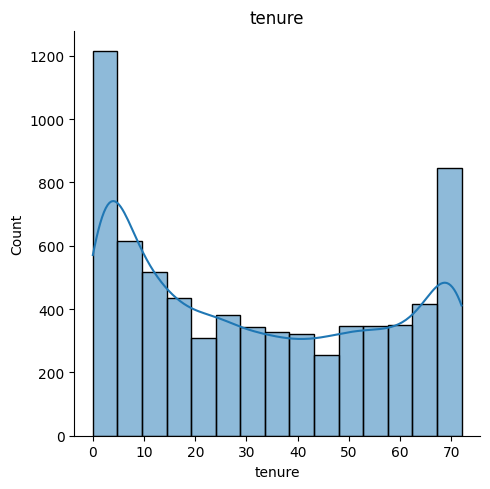

<Figure size 800x600 with 0 Axes>

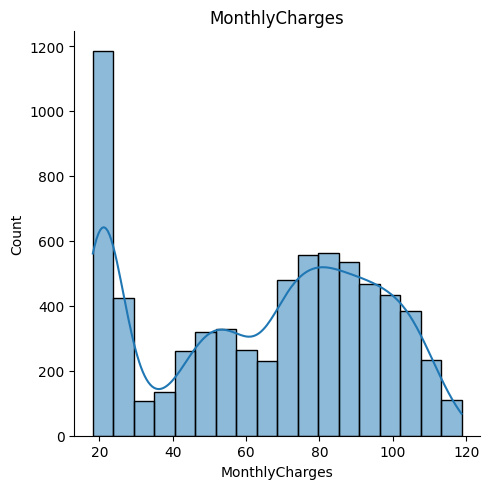

<Figure size 800x600 with 0 Axes>

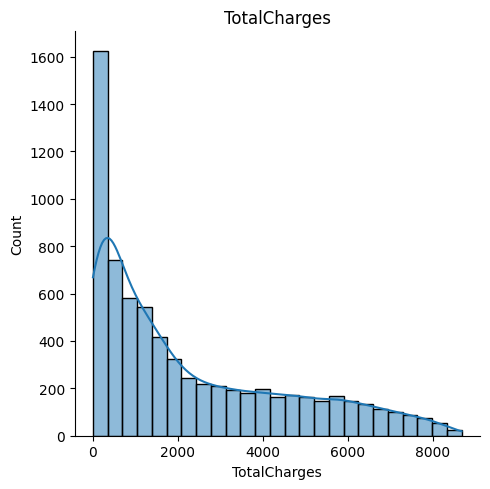

In [ ]:
for column in num_column:
 plt.figure(figsize=(8,6))
 sns.displot(df,x=column, kde=True)
 plt.title(column)
 plt.tight_layout()
 plt.show()


#### Analysis Report

**Tenure**
* Min tenure is 0 and Maximum tenure is 72.
* Between 0 to 10 there is lot of data point almost 25%. It indicate chance of churn is high here.
* The graph is multi peak there is lot of customer who haven't churn till 70 month but in terms of count it is less compare to first peak (0-5).
* Tenure between 20 to 65 count is almost same.


**Monthly Charge**
* Minmum monthly charge is 18 and maximum monthly charge is 119.
* A large group of customer has basic plan between 20-30.
* Another large group of customer lies between 65 to 105.

**TotalCharge**
* Mean is 2290 and max value is 8684 and 75% of customers monthly bull is less than 3807, meaning data is highly right skewed.
* Max customer pays less than 2000.
* Between 3000 and 5000 customer count is constant but count is less.
* Customer are very less who pays more than 8000, May be outlier is present.



<!--  -->

### Categorical Columns

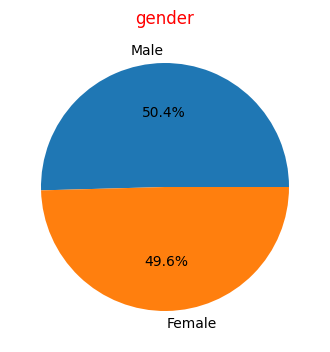

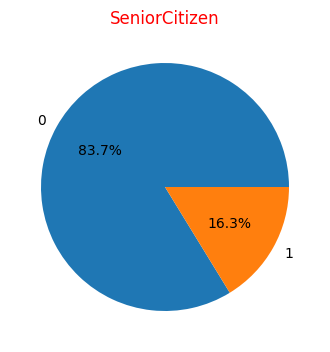

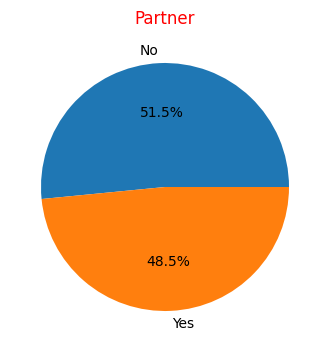

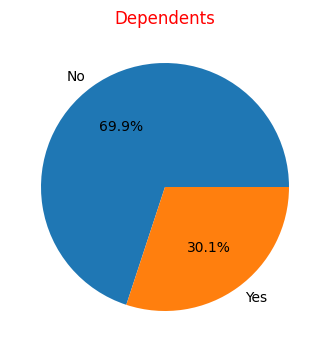

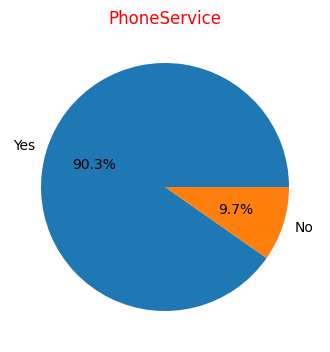

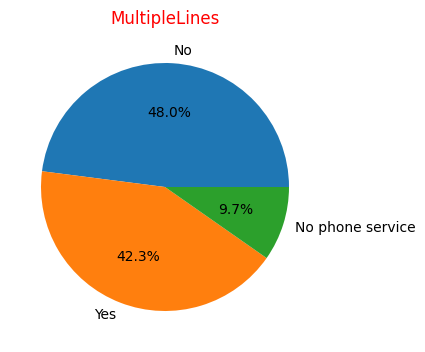

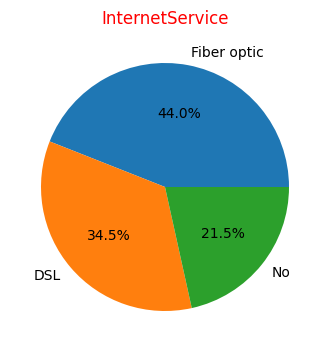

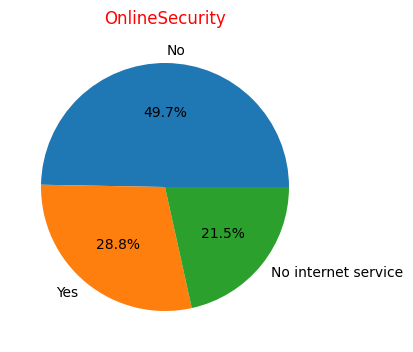

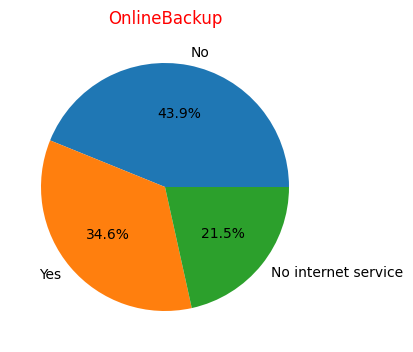

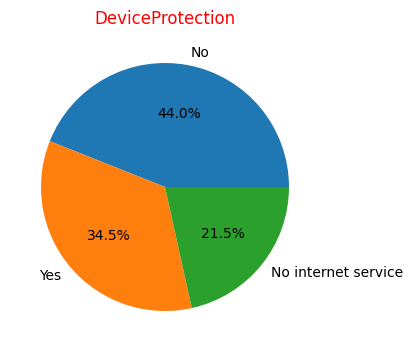

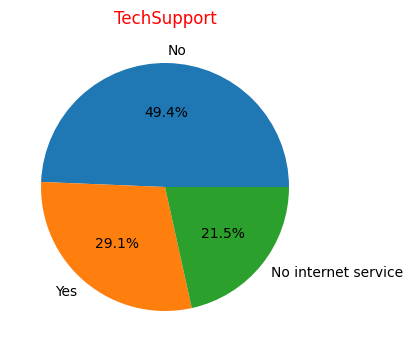

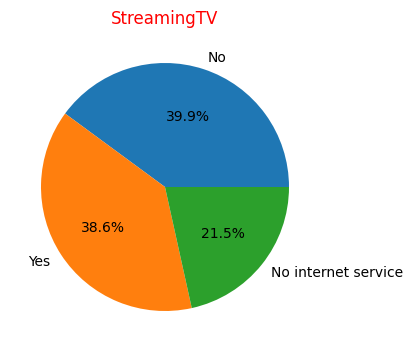

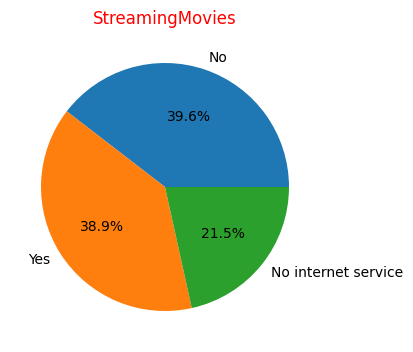

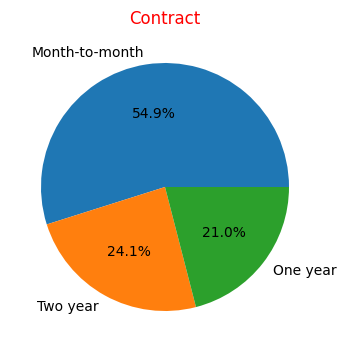

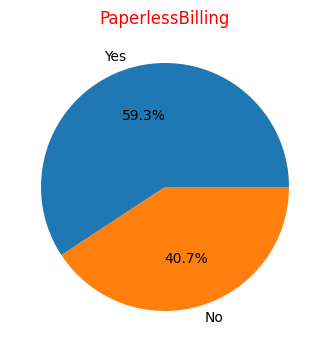

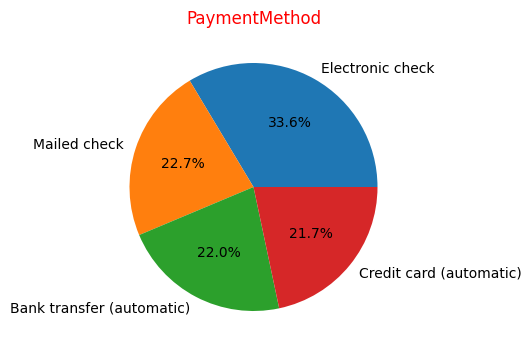

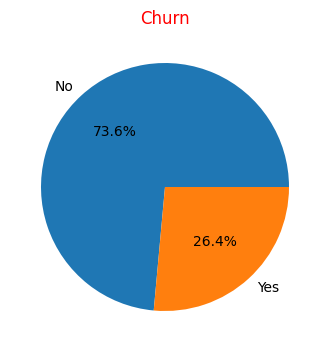

In [ ]:
for col in cat_column:
    plt.figure(figsize=(4,8))
    val = df[col].value_counts()
    labels = val.index
    values = val.values
    plt.pie(x=values, labels=labels ,autopct="%0.1f%%")
    plt.title(col, color='r')
    # plt.tight_layout()
    # plt.legend()
    plt.show()

#### Analysis Report

**Gender**
* Dataset has 50% male and 50% female customer.

**SeniorCitizen**
* Only 16% customer is seniorcitizen and rest are not.

**Partner**
* Gap is too small meaning customer has partner and not both are equal.
* 49% of customer has partner and 51% customer has No partner.

**Dependents**
* 70% customers not support family for now and 30% customers support family.
* almost more than double customers are independent.

**PhoneServices**
* Most of the customers using phone services.
* Little amount of customers are not using phone sevices that is 9.4%.

**Multiple Line**
* 43% customers uses mltiple line and 48% customer using single line.
* Here gap is low that is 5%.

**Internet Service**
* 44% customer uses fiber cable internet.
* 34% customer uses DSL internet.
* almost 22% customer not have internet service.

**Online security**
* Almost 50% customer don't have any online security.
* 29% customer has online security.
* we can say almost 70% customer don't have any kind of online secrity plan if add No internet service customer.

**Online backup**
* 35% customer have purchased Online backup subscription.
* if we add No and no internet service customer then we can say large number of customers don't have online backup plan and percentage 65%.

**Device Protection**
* 34% customers has Device protection plan which almost eaqual to Online backup plan. May be there is similarity between these to we will check in Bi-variate analysis.

* 66%  customers don't have any device protection plan if we add No internet service customers with No customers.

**TechSupport**
* ALmost Half of the customers not subscribed any tech support plan but they have internet service.
* 29% customer who has tec support plan.


**Streaming TV** **AND** **Streaming Movies**
* 39% customer watching tv and movies that means they subscribed these services.
* 40% customers has internet but no subscription of these type.

**Contract**
* More than 50% customers pays bill monthly.
* 24% cutomers has two year plan and 21% customer has one year plan.
* Here gap is 3%.

* Paperless Billing**
* Almost 60% customers loves paperless bill and 40% customer uses paper billing.

**Payment Method**
* All payment methods has good amount of customer.
* Among these Electronic check is most used payment method and others are almost equal.

**Churn**
* 73.5% customers not churn and churn customers percentage is 26%.
* Meaning dataset is imbalanced. And ration is 75:27

<!--  -->

<!--  -->

## BI-Variate Analysis

<!--  -->

### Numerical Variable

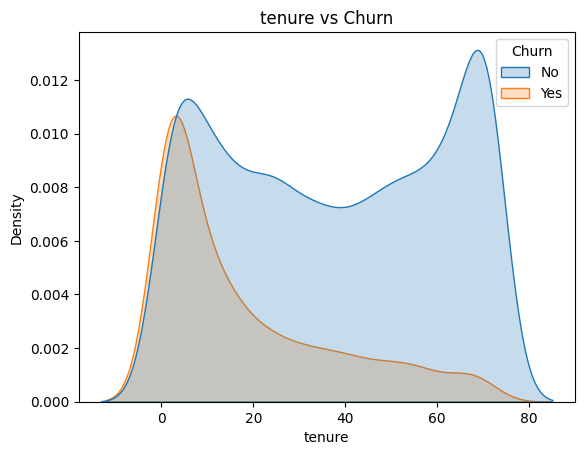

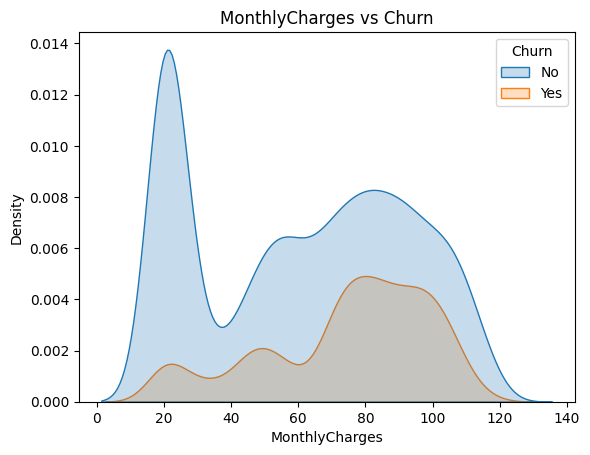

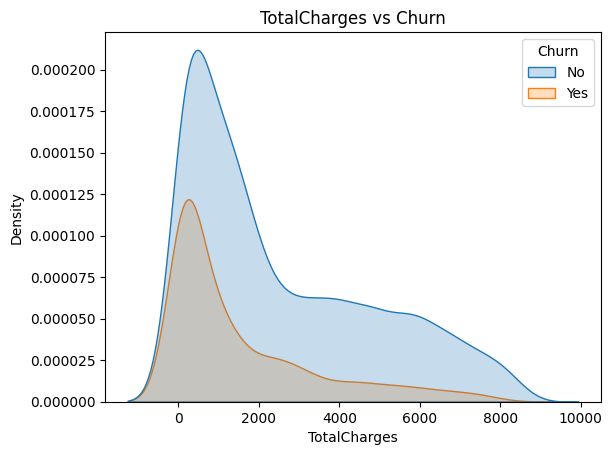

In [ ]:

for col in num_column:
    sns.kdeplot(df, x=col,fill=True,hue='Churn')
    plt.title(f'{col} vs Churn')
    plt.show()

### Analysis Report

**Tenure vs Churn**
* When tenure is short (0 - 10) chances of churn is high.
* When tenure close to 20 or more than 20 chances start to decresing exponentialy.

**Monthly Charge vs Churn**
* Charge till 60 chance of Churn is low.
* Charge between 65 to 115 has high chance of Churn.
* Close to 120 and afterward Churn chnace is very low almost no churn.

**TotalCharge vs Churn**
* It is combination of tenure and MonthlyCharge.
* short charge high chance of Churn and when Charge increases chance of churn decreases.

<!--  -->

### Categorical Variable

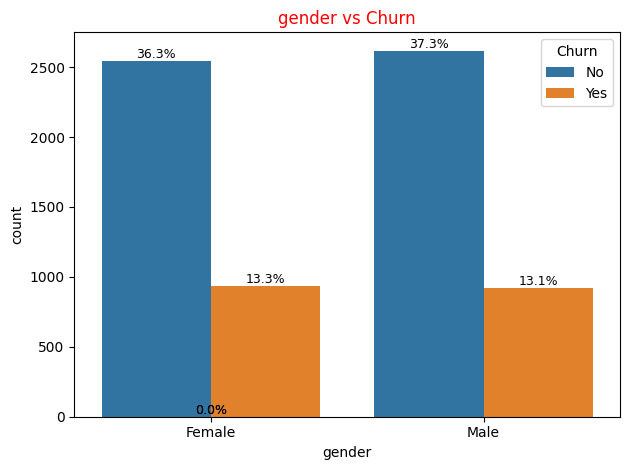

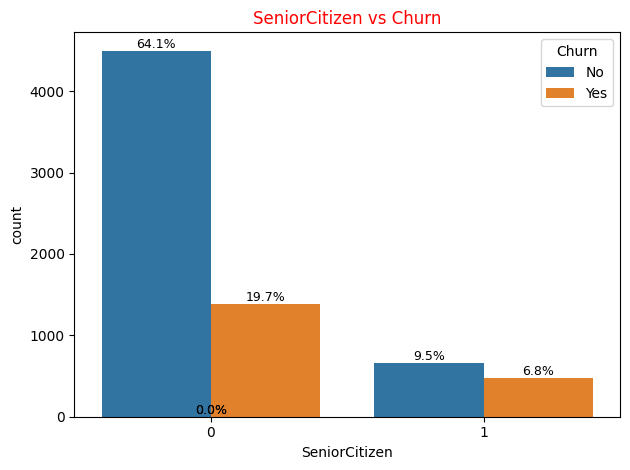

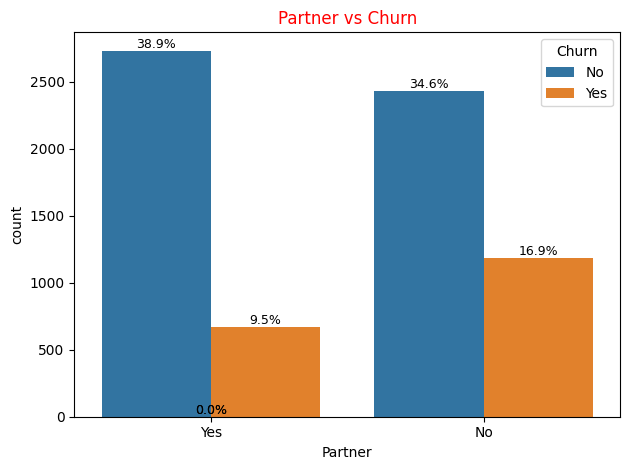

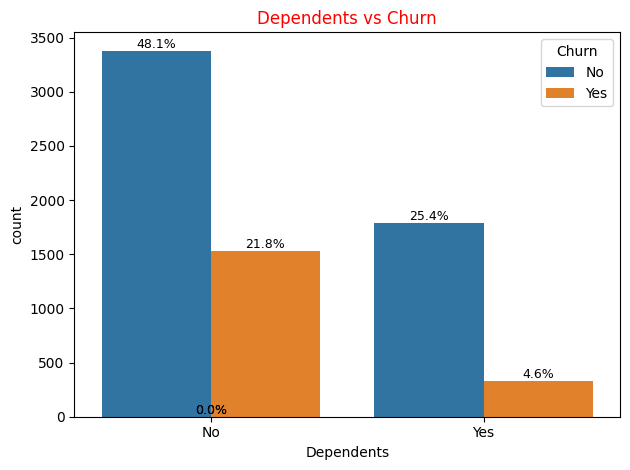

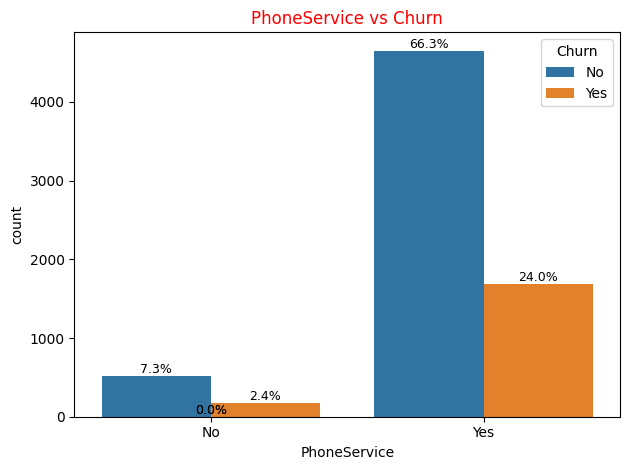

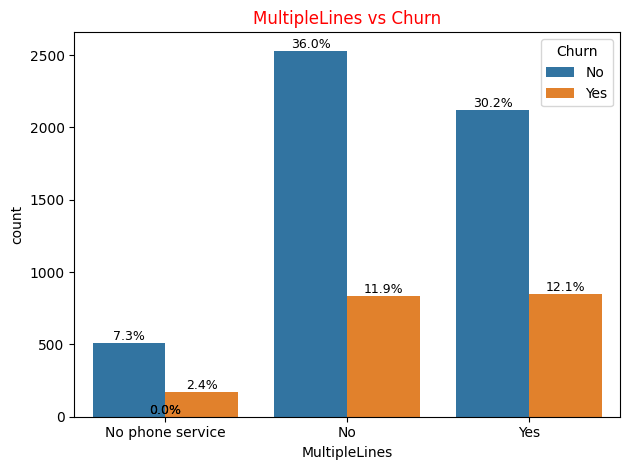

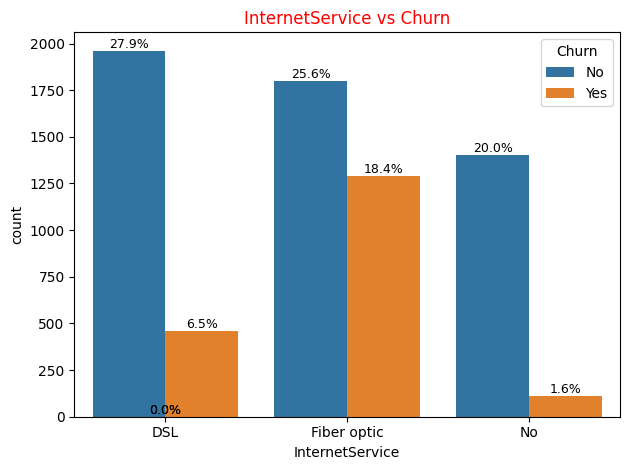

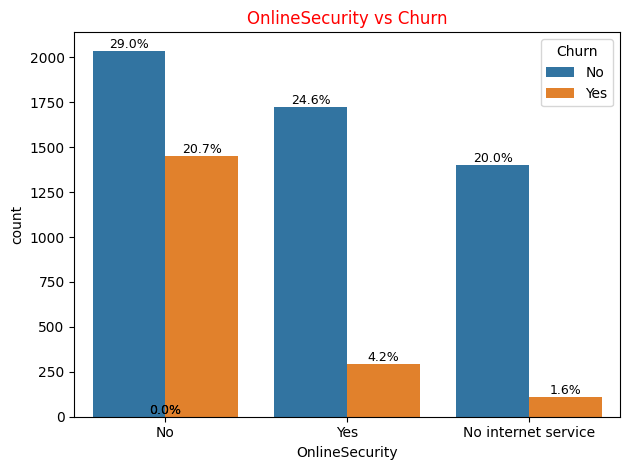

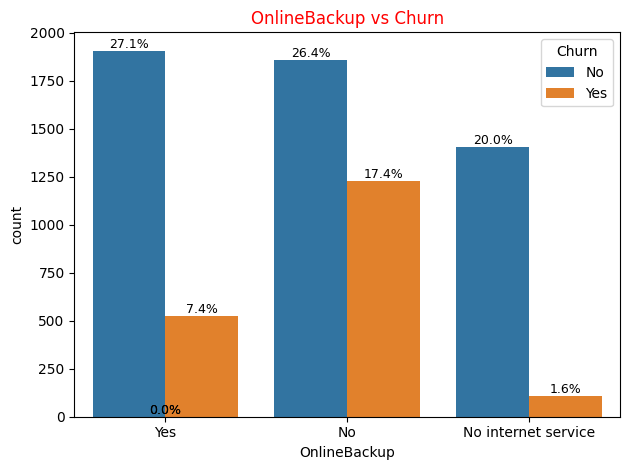

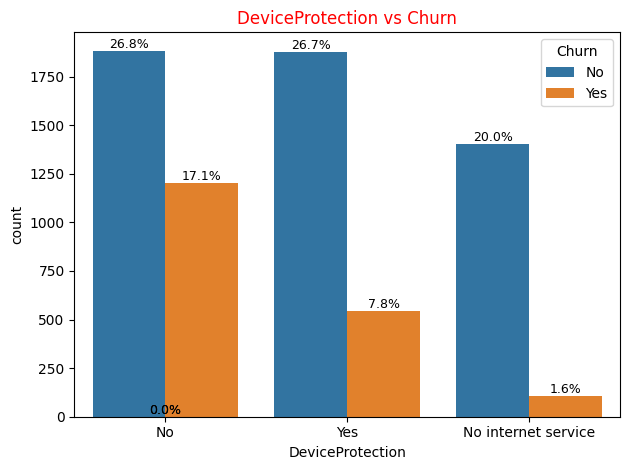

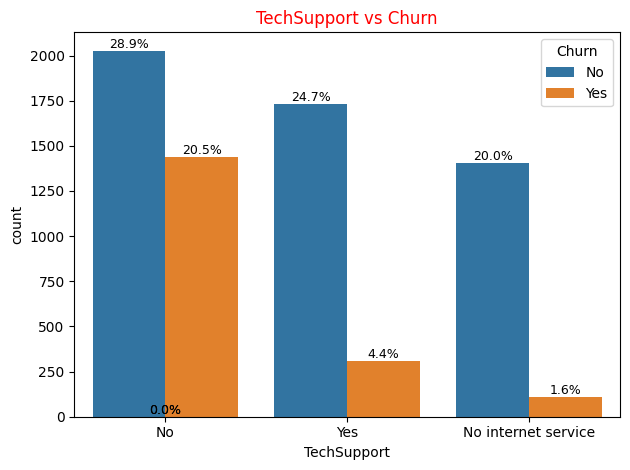

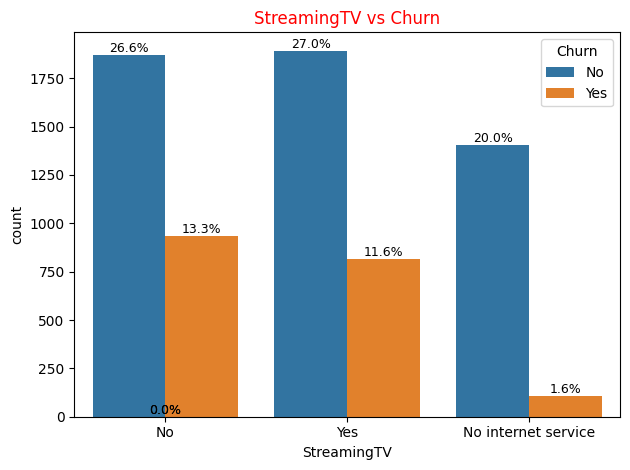

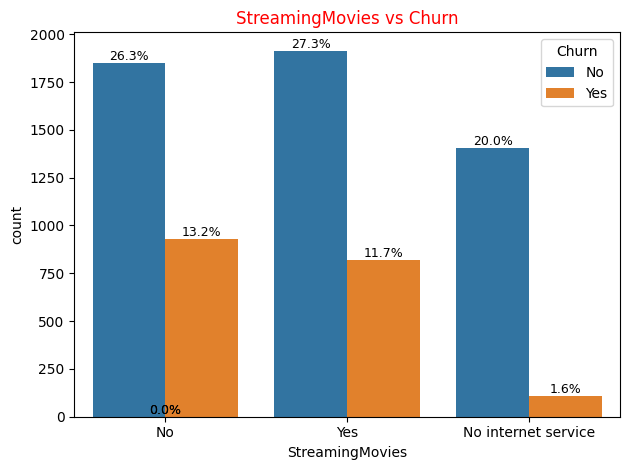

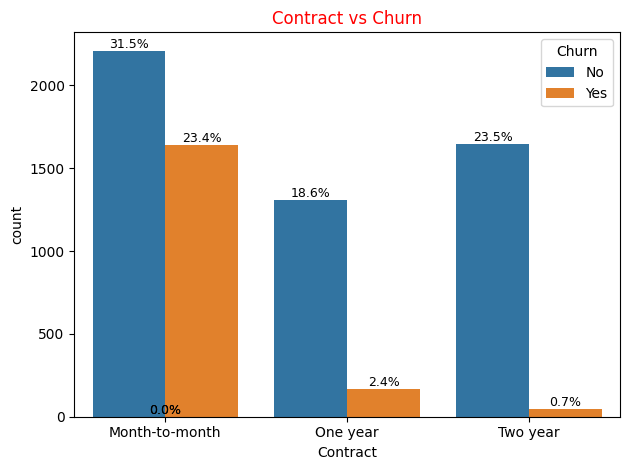

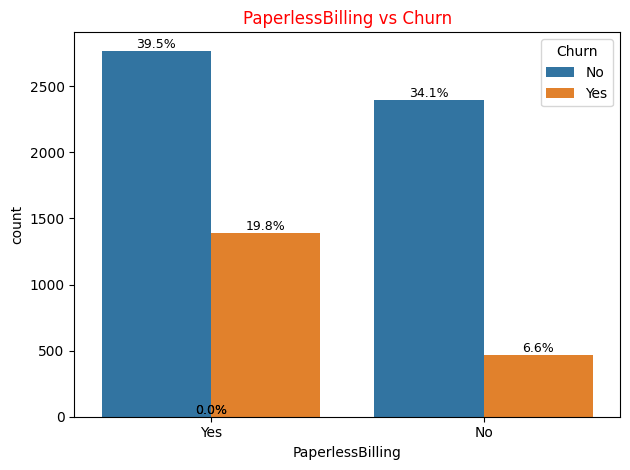

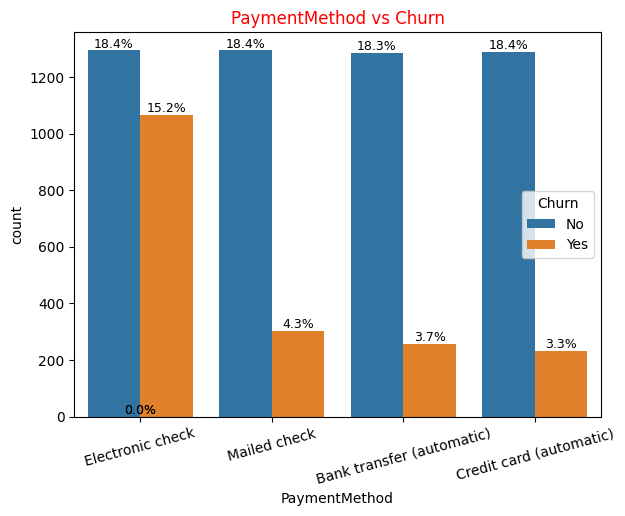

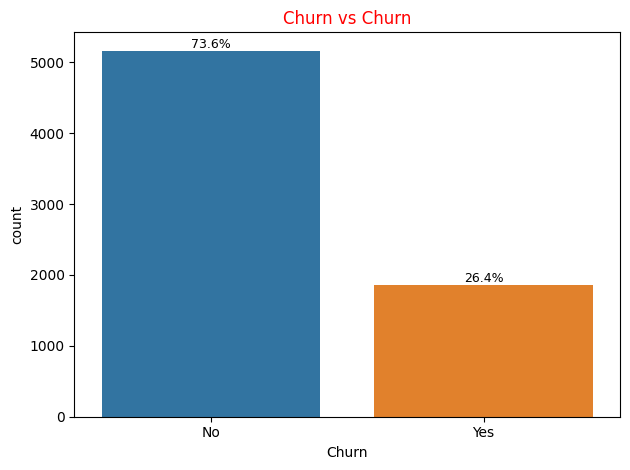

In [ ]:
for col in cat_column:
    ax = sns.countplot(df, x=col, hue='Churn')

    # Calculate total counts for percentage
    total = len(df)

    # Loop through bars and add percentage labels
    for p in ax.patches:
        height = p.get_height()
        percentage = 100 * height / total
        ax.annotate(f'{percentage:.1f}%',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=9, color='black')
    plt.title(f'{col} vs Churn',color='red')
    plt.tight_layout()
    if col == 'PaymentMethod':
     plt.xticks(rotation=15)
    plt.show()

### Analysis Report



**Gender VS Churn**
* Female customer churn rate is 26.8% and Male customer churn rate is 26%.
* Both gender shows almost equal churn rate So we can say gender does not affect Churn probability.
* Also count is almost same for each gender in dataset.

**SeniorCitizen VS Churn**
* Non senior churn rate is 24% and  Senior customer churn rate is 42%, So here Senior citizen has high churn rate.
* Sineor citizen has 25% churn rate of overall churn but data is only 16%.

**Partner VS Churn**
* Cutomer with partner has 20% churn rate and Customer with no partner has 33% churn.
* Clearly customer with no partner has high curn rate.

**Dependent vs Churn**
* Without Dependent customer has 31% churn and with dependent customer has 15% churn rate.
* So Without dependent customer has almost double chance of churn.

**PhoneServices vs Churn**
* Cutomer with no phone service has 25% of churn , But it contain only 10% data.
* Customer with phone service has 26% of churn rate , But it contain 90% data.
* So Having phone service has negligible impact on overall churn.
* But mass volumn has phone sevice and has 26% churn rate
so we have think on that.

**MultipleLine vs Churn**
* Single line customers has 25% churn and multi line customers has 28% of churn.
* So Having multiline service has very small amount of impact on churn.

**Internet Service Vs Churn**
* Customer with DSL internet service has 19% churn.
* Customer with fiber optic internet service has 42% churn.
* Customer with no internet service has 7% chance of churn.
* Customer with fiber optic internet service has high chance churn almost double compare to DSL.
* So Internet service effect the over all churn.

**Online security vs Churn**
* Customer not having Online security subscription has 42% chance of churn.
* Customer having online security subscription has 15% chance of churn.
* So Nt having oline security subscription has almost 3 times high chance of churn.
* So yes it impact over all churn.

**Online backup Vs Churn**
* Customer not having Online backup subscription has 23% chance of churn.
* Customer having Online Backup subscription has 39% chance of churn.
* Having online backup has more than 1.5 times or near to double chance of churn.
* So yes this feature has imapct on overall churn.

**Device protection Vs Churn**
* Customer with no device prtection subscription has 39% chance of churn.
* Customer with Device protection plan has 22% of churn.
* Here also Without Device protection plan customer has almost or near double chance of churn.
so yes this feature has inpact on overall churn.

**Tech Support Vs churn**
* without tech support plan customers has 41% of churn and with tect support plan customers has 15% churn chance.
* Clearly Not having tech support customer has more than double chance of churn.
* So this feature has impact on over all churn.

**StreamingTV vs Churn**
* Customer who streaming TV has 30% chance of churn
and No streaming TV has 33%.
* So this feature has minimal impact on overall churn.

**Streaming Movie and Churn**
* who stream movie has 30% chance of churn and who not stream movie has 33%.
* this feature has minimal impact on overall churn.
* i think streaming movie and streaming tv is corelated with each other we will check on multicolinarity segment.

**Contract vs Churn**
* Cusomer who pays Month-to-month bill has 43% chance of churn and who pays yearly bill has 11% chance of churn and who pays bill in two year 2% chance churn.
* churn rate : Month-to-mont >>>> One-year >> two year.
* it indicate contract has big impact on churn.

**PaperlessBilling VS Churn**
* Customer who choose paperless billing has 33% chance of churn and no paperless billing has 16% chance of Churn.
* CUstomer who choose paperless billing has 2 times high chance of Churn.
* so it has impact on overall churn.

**PaymentMethod vs Churn**
* Customer who pays bill using electronic check has 45% churn chance.
* Customer who pays bill using mailed check has 18% churn chance.
* Customer who pays bill using bank transfer(automatic) has 17% churn chance.
* Customer who pays bill using credit card has 15% churn chance.
* If customer pays bill using electronic has very high chance of churn, Others has equal impact on churn probability.

**Churn vs Churn**
* Loking overall churn data clearly it indicate dataset is imbalance.

<!--  -->

# Relation between variable

<!--  -->

### Relation Between Numerical Features

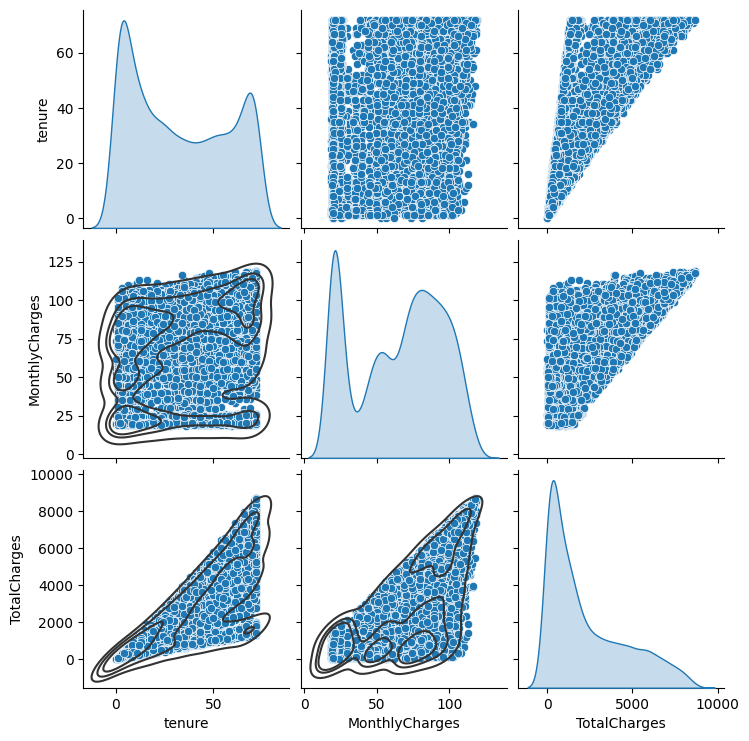

In [ ]:
graph = sns.pairplot(data=df[num_column], kind='scatter', diag_kind = "kde")
graph.map_lower(sns.kdeplot, levels = 4, color = ".2")
plt.show()

In [ ]:
from scipy.stats import spearmanr

num_df = df[num_column]
spearman_corr = num_df.corr(method='spearman')
spearman_corr

,tenure,MonthlyCharges,TotalCharges
tenure,1.00000,0.27355,0.88872
MonthlyCharges,0.27355,1.00000,0.63704
TotalCharges,0.88872,0.63704,1.00000


#### INSIGHT
* TotalCharges has higly correlated with tenure because it is multiplication of tenure and MonthlyCharge.
* So we are removing Total charge.

In [ ]:
# num_column.remove('TotalCharges')

<!--  -->

### Relation Between Categorical Features

In [ ]:

from scipy import stats

# cat_column1 = cat_column.copy()
# cat_column1.remove('Churn')
def catVsCatRelation(df,cat_column):
        results = []

        # print("=== CHI-SQUARE TESTS FOR CATEGORICAL FEATURES ===\n")

        for i, col1 in enumerate(cat_column):
            # for col2 in cat_column:
            for col2 in cat_column[i+1:]:
                # if col2 == col1 : continue

                # Create Contingency Table (Cross-tabulation)
                table = pd.crosstab(df[col1], df[col2])

                # Check for cells with low expected counts (< 5)
                # Chi-square assumptions require expected counts >= 5 for most cells
                expected = stats.chi2_contingency(table)[3]
                low_counts = (expected < 5).sum()

                # Perform Chi-Square Test
                chi2, p, dof, expected_counts = stats.chi2_contingency(table)

                # Calculate Effect Size (Cramér's V)
                n = table.sum().sum()
                r, c = table.shape
                # Bias correction for small samples (optional but recommended)
                phi2 = chi2 / n
                phi2_corr = max(0, phi2 - ((c-1)*(r-1))/(n-1))
                r_corr = r - ((r-1)**2)/(n-1)
                c_corr = c - ((c-1)**2)/(n-1)
                cramers_v = np.sqrt(phi2_corr / min(c_corr-1, r_corr-1)) if min(c_corr-1, r_corr-1) > 0 else 0


                results.append({
                    'Feature A': col1,
                    'Feature B': col2,
                    'Chi-Square': chi2,
                    'P-Value': p,
                    'Cramers_V': cramers_v,
                    'Low_Expected_Counts': low_counts,
                    'Strength': 'Large' if cramers_v > 0.3 else ('Medium' if cramers_v > 0.1 else 'Small')
                })

                # Print top 5 significant relationships
                if p < 0.05 and len(results) <= 5:
                    print(f"{col1} vs {col2}: V={cramers_v:.3f}, p={p:.2e}")

        # 3. View Results
        results_df = pd.DataFrame(results)
        results_df = results_df.sort_values('Cramers_V', ascending=False)
        return results_df

        # print("\n--- TOP 10 STRONGEST CATEGORICAL RELATIONSHIPS ---")
        # results_df[['Feature A', 'Feature B', 'Cramers_V', 'P-Value']].head(10)


In [ ]:
results_df = catVsCatRelation(df,cat_column)

In [ ]:
pd.concat([results_df[results_df['Feature A'] == 'Churn'],results_df[results_df['Feature B'] == 'Churn']],axis=0)[['Feature A',	'Feature B','Cramers_V']]


,Feature A,Feature B,Cramers_V
132,Contract,Churn,0.409607
99,OnlineSecurity,Churn,0.346900
120,TechSupport,Churn,0.342397
90,InternetService,Churn,0.322485
135,PaymentMethod,Churn,0.302158
107,OnlineBackup,Churn,0.291614
114,DeviceProtection,Churn,0.280893
129,StreamingMovies,Churn,0.230693
125,StreamingTV,Churn,0.230268
134,PaperlessBilling,Churn,0.190202


In [ ]:
selected_df = results_df[results_df['Cramers_V'] >= 0.5][['Feature A', 'Feature B', 'Cramers_V']]

In [ ]:
selected_df

,Feature A,Feature B,Cramers_V
58,PhoneService,MultipleLines,0.999929
121,StreamingTV,StreamingMovies,0.770742
110,DeviceProtection,StreamingMovies,0.735782
109,DeviceProtection,StreamingTV,0.733400
93,OnlineSecurity,TechSupport,0.732867
108,DeviceProtection,TechSupport,0.726271
81,InternetService,OnlineSecurity,0.724345
84,InternetService,TechSupport,0.722782
101,OnlineBackup,TechSupport,0.719633
100,OnlineBackup,DeviceProtection,0.718910


In [ ]:
import pandas as pd

cramers_V_df = results_df[['Feature A',	'Feature B','Cramers_V']]
# Your pairwise values as a list of dictionaries

# Create square matrix
features = list(set(cramers_V_df["Feature A"]).union(set(cramers_V_df["Feature B"])))
cramers_v_matrix = pd.DataFrame(1.0, index=features, columns=features)

for _, row in cramers_V_df.iterrows():
    a, b, v = row["Feature A"], row["Feature B"], row["Cramers_V"]
    cramers_v_matrix.loc[a,b] = v
    cramers_v_matrix.loc[b,a] = v


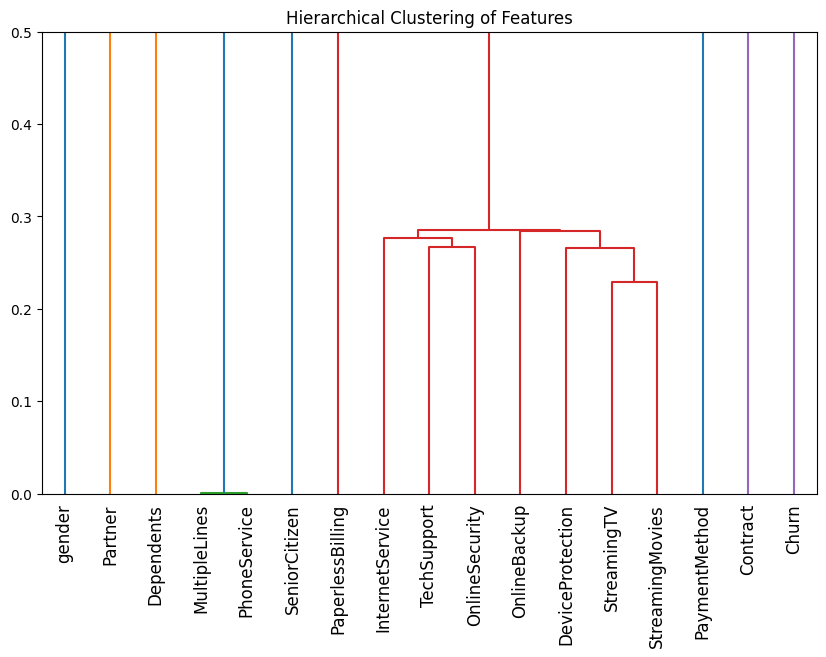

In [ ]:
import pandas as pd
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

# Suppose you already have a Cramér’s V matrix (values between 0 and 1)
# Convert to distance
distance_matrix = 1 - cramers_v_matrix

# Convert square matrix to condensed form
condensed = squareform(distance_matrix.values)

# Use average linkage (better for categorical similarity)
linkage_matrix = linkage(condensed, method="average")

# Plot dendrogram with controlled y-axis
plt.figure(figsize=(10,6))
dendrogram(linkage_matrix, labels=cramers_v_matrix.index, leaf_rotation=90)
plt.ylim(0, 0.5)  # force scale to show only 0–0.5 distances
plt.title("Hierarchical Clustering of Features")
plt.show()



<!--  -->

### Relation Between Numerical and categorical column

In [ ]:
from scipy.stats import mannwhitneyu, kruskal
import numpy as np
import pandas as pd

def numerical_vs_categorical_analysis(df, numerical_cols, categorical_cols, target_col=None, alpha=0.05):
    """
    Perform statistical tests between numerical features and categorical variables.

    Automatically chooses Mann-Whitney U (2 categories) or Kruskal-Wallis (3+ categories).

    Parameters:
    - df: DataFrame
    - numerical_cols: list of numerical column names
    - categorical_cols: list of categorical column names to test against numerical features
    - target_col: optional specific target column (if None, tests all categorical columns)
    - alpha: significance level

    Returns: DataFrame with comprehensive test results
    """
    from scipy.stats import mannwhitneyu, kruskal

    results = []

    # Determine which categorical columns to test
    test_columns = [target_col] if target_col else categorical_cols

    for cat_col in test_columns:
        # Skip if categorical column doesn't exist
        if cat_col not in df.columns:
            print(f"Warning: '{cat_col}' not found in DataFrame")
            continue

        # Get unique categories
        categories = df[cat_col].dropna().unique()
        n_categories = len(categories)

        # print(f"\n{'='*60}")
        # print(f"Testing {cat_col} ({n_categories} categories): {categories}")
        # print(f"{'='*60}")

        for num_col in numerical_cols:
            # Skip if numerical column doesn't exist
            if num_col not in df.columns:
                continue

            # Prepare data
            groups = []
            group_names = []

            for cat in categories:
                group_data = df[df[cat_col] == cat][num_col].dropna()
                if len(group_data) > 0:  # Only include non-empty groups
                    groups.append(group_data)
                    group_names.append(f"{cat_col}={cat}")

            # Skip if not enough groups
            if len(groups) < 2:
                continue

            # Choose appropriate test
            if n_categories == 2:
                # Mann-Whitney U test (2 groups)
                group1, group2 = groups[0], groups[1]
                name1, name2 = group_names[0], group_names[1]

                u_stat, p_val = mannwhitneyu(group1, group2, alternative='two-sided')

                # Effect size (rank-biserial correlation)
                n1, n2 = len(group1), len(group2)
                r = 1 - (2 * u_stat) / (n1 * n2)

                # Medians
                med1, med2 = group1.median(), group2.median()

                test_name = "Mann-Whitney U"

            else:
                # Kruskal-Wallis test (3+ groups)
                h_stat, p_val = kruskal(*groups)

                # Effect size (eta-squared approximation)
                # eta² = H / (N - 1) where N = total sample size
                N = sum(len(g) for g in groups)
                eta_sq = h_stat / (N - 1)

                # Medians for each group
                medians = [g.median() for g in groups]

                test_name = "Kruskal-Wallis"

                # For Kruskal-Wallis, we need post-hoc pairwise tests
                # (simplified here - just report overall test)
                r = eta_sq  # Use eta-squared as effect size
                med1, med2 = medians[0], medians[1] if len(medians) >= 2 else medians[0]

            # Determine significance and interpretation
            significant = p_val < alpha

            # Effect size interpretation
            if test_name == "Mann-Whitney U":
                if abs(r) > 0.5:
                    effect_mag = "Large"
                elif abs(r) > 0.3:
                    effect_mag = "Medium"
                elif abs(r) > 0.1:
                    effect_mag = "Small"
                else:
                    effect_mag = "Negligible"

                # Direction for 2-group test
                if r < 0:
                    direction = f"{name1} < {name2}"
                elif r > 0:
                    direction = f"{name1} > {name2}"
                else:
                    direction = "Equal"

            else:  # Kruskal-Wallis
                if abs(r) > 0.14:
                    effect_mag = "Large"
                elif abs(r) > 0.06:
                    effect_mag = "Medium"
                elif abs(r) > 0.01:
                    effect_mag = "Small"
                else:
                    effect_mag = "Negligible"

                direction = f"Group differences (eta²={r:.3f})"

            results.append({
                'Numerical_Feature': num_col,
                'Categorical_Variable': cat_col,
                'Test': test_name,
                'U_or_H_Statistic': round(u_stat if test_name == "Mann-Whitney U" else h_stat, 3),
                'p_value': round(p_val, 6),
                'Significant': significant,
                'Effect_Size': round(r, 4),
                'Effect_Magnitude': effect_mag,
                'Direction': direction,
                'Median_Group1': round(med1, 2),
                'Median_Group2': round(med2, 2) if test_name == "Mann-Whitney U" else "N/A"
            })

    return pd.DataFrame(results)

all_results = numerical_vs_categorical_analysis(
    df,
    numerical_cols=num_column,
    categorical_cols=cat_column
)



In [ ]:
all_results[['Numerical_Feature','Categorical_Variable','Effect_Size','Significant']]

,Numerical_Feature,Categorical_Variable,Effect_Size,Significant
0,tenure,gender,0.0056,False
1,MonthlyCharges,gender,-0.0145,False
2,TotalCharges,gender,0.0001,False
3,tenure,SeniorCitizen,0.0267,False
4,MonthlyCharges,SeniorCitizen,0.3448,True
5,TotalCharges,SeniorCitizen,0.1674,True
6,tenure,Partner,-0.4413,True
7,MonthlyCharges,Partner,-0.1225,True
8,TotalCharges,Partner,-0.3896,True
9,tenure,Dependents,0.2035,True


<!--  -->

# Model Prepration

#### Creating Test

In [ ]:
df['Churn'].value_counts(normalize=True)

,proportion
Churn,
No,0.735508
Yes,0.264492


In [ ]:
X = df.drop('Churn',axis=1)
y = df['Churn']

In [ ]:
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.2,stratify=y,random_state=42)

In [ ]:
print('X_train shape : ',X_train.shape)
print('y_train shape : ',y_train.shape)
print('X_test shape : ',X_test.shape)
print('y_test shape : ',y_test.shape)

X_train shape :  (5616, 19)
y_train shape :  (5616,)
X_test shape :  (1405, 19)
y_test shape :  (1405,)


In [ ]:
tr_df_c = pd.concat([X_train , y_train ] ,axis=1)

<!--  -->

### Fixixng the bimodel issue in Tenure

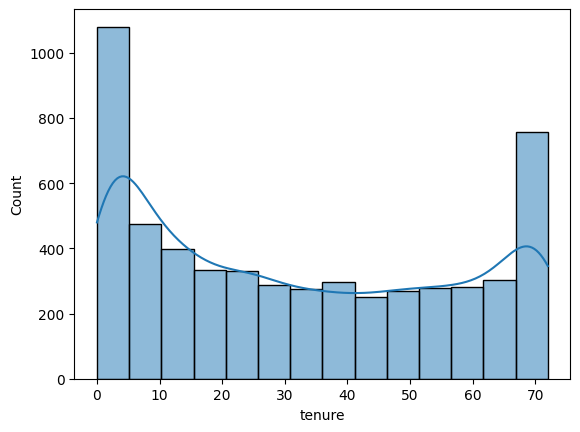

In [ ]:
sns.histplot(tr_df_c, x='tenure' , label="Tenure",kde=True)
plt.show()

In [ ]:
bins=[0, 6, 12, 24, 60, np.inf]
labels = ['0-6m', '6-12m', '1-2y', '2-5y', '5+y']
tr_df_c['Tenure_cat'] = pd.cut(tr_df_c['tenure'],bins=bins,labels=labels)

In [ ]:
catVsCatRelation(tr_df_c,['Tenure_cat','Churn'] )

Tenure_cat vs Churn: V=0.361, p=1.03e-157


,Feature A,Feature B,Chi-Square,P-Value,Cramers_V,Low_Expected_Counts,Strength
0,Tenure_cat,Churn,734.767252,1.031855e-157,0.361046,0,Large


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
from xgboost import XGBClassifier
import numpy as np
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder

# Continuous tenure (original)
X_cont = tr_df_c[['tenure']].copy()

# Binned tenure (your new features)
X_bin = pd.DataFrame(OrdinalEncoder().fit_transform(tr_df_c[['Tenure_cat']]))

# Encode target
y = tr_df_c['Churn'].map({'Yes': 1, 'No': 0})

# Split data
train_Xc, test_Xc, train_y, test_y = train_test_split(X_cont, y, test_size=0.2, random_state=42, stratify=y)
train_Xb, test_Xb, _, _ = train_test_split(X_bin, y, test_size=0.2, random_state=42, stratify=y)

# Train models
model_c = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
model_b = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')

model_c.fit(train_Xc, train_y)
model_b.fit(train_Xb, train_y)

# Evaluate
pred_c = model_c.predict(test_Xc)
pred_b = model_b.predict(test_Xb)

# print(f"Continuous Tenure: AUC={roc_auc_score(test_y, pred_c):.4f}, Accuracy={accuracy_score(test_y, pred_c):.4f}")
# print(f"Binned Tenure:     AUC={roc_auc_score(test_y, pred_b):.4f}, Accuracy={accuracy_score(test_y, pred_b):.4f}")
print(f"Difference:        AUC={roc_auc_score(test_y, pred_b) - roc_auc_score(test_y, pred_c):+.4f}")
print(f"Difference of f1 : f1={f1_score(test_y, pred_b) - f1_score(test_y, pred_c):+.4f}"  )


Difference:        AUC=+0.0165
Difference of f1 : f1=+0.0401


#### Insight:
* Here roc_auc and f1 score increased after binning so we will keep binning and remove continuous tenure.

<!--  -->

### Fxixing Bimodel issue in MonthlyCharge

<Axes: xlabel='MonthlyCharges', ylabel='Count'>

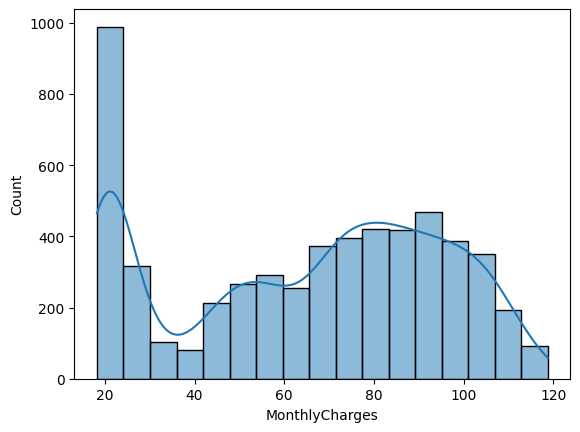

In [ ]:
sns.histplot(tr_df_c["MonthlyCharges"],kde=True, label="MonthlyChanrge")

In [ ]:
df['MonthlyCharges'].describe()

,MonthlyCharges
count,7021.000000
mean,64.851894
std,30.069001
min,18.250000
25%,35.750000
50%,70.400000
75%,89.900000
max,118.750000


In [ ]:
bins = [18,35,45,65,105,120,np.inf]
labels = ['low','low-mid','mid','high-mid','high','highest']
tr_df_c['MonthlyCharges_cat'] = pd.cut(tr_df_c['MonthlyCharges'],bins=bins,labels=labels)

In [ ]:
catVsCatRelation(tr_df_c,['MonthlyCharges_cat','Churn'] )

MonthlyCharges_cat vs Churn: V=0.248, p=2.16e-74


,Feature A,Feature B,Chi-Square,P-Value,Cramers_V,Low_Expected_Counts,Strength
0,MonthlyCharges_cat,Churn,349.584919,2.155756e-74,0.248086,0,Medium


In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score
from xgboost import XGBClassifier
import numpy as np
from sklearn.preprocessing import LabelEncoder,OrdinalEncoder

# Continuous tenure (original)
X_cont = tr_df_c[['MonthlyCharges']].copy()

# Binned tenure (your new features)
X_bin = pd.DataFrame(OrdinalEncoder().fit_transform(tr_df_c[['MonthlyCharges_cat']]))

# Encode target
y = tr_df_c['Churn'].map({'Yes': 1, 'No': 0})

# Split data
train_Xc, test_Xc, train_y, test_y = train_test_split(X_cont, y, test_size=0.2, random_state=42, stratify=y)
train_Xb, test_Xb, _, _ = train_test_split(X_bin, y, test_size=0.2, random_state=42, stratify=y)

# Train models
model_c = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
model_b = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')

model_c.fit(train_Xc, train_y)
model_b.fit(train_Xb, train_y)

# Evaluate
pred_c = model_c.predict(test_Xc)
pred_b = model_b.predict(test_Xb)

# print(f"Continuous Tenure: AUC={roc_auc_score(test_y, pred_c):.4f}, Accuracy={accuracy_score(test_y, pred_c):.4f}")
# print(f"Binned Tenure:     AUC={roc_auc_score(test_y, pred_b):.4f}, Accuracy={accuracy_score(test_y, pred_b):.4f}")
print(f"Difference:        AUC={roc_auc_score(test_y, pred_b) - roc_auc_score(test_y, pred_c):+.4f}")
print(f"Difference of f1 : f1={f1_score(test_y, pred_b) - f1_score(test_y, pred_c):+.4f}"  )


Difference:        AUC=-0.0157
Difference of f1 : f1=-0.1285


#### Checking outlier in Monthly Charge


<Axes: ylabel='MonthlyCharges'>

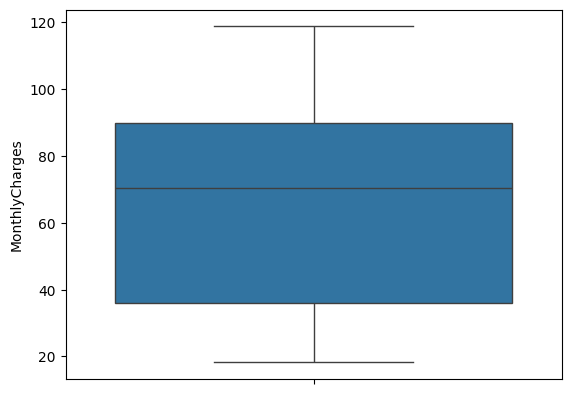

In [ ]:

sns.boxplot(tr_df_c,y='MonthlyCharges')

#### Insight
* Here roc_auc score and f1 score both decreases after binning so we will not keep bining.
* There is no outlier in MonthlyCharge.

<!--  -->

### Applying Encodding on Categorical Features And Normalize the Features

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

class TenureBinningTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, bins=[0, 6, 12, 24, 60, np.inf], labels=['0-6m', '6-12m', '1-2y', '2-5y', '5+y']):
        self.bins = bins
        self.labels = labels

    def fit(self, X, y=None):
        return self

    def get_feature_names_out(self, input_features=None):
        return np.array(["Tenure_Category"])

    def transform(self, X):
        X = pd.DataFrame(X) if not isinstance(X, pd.DataFrame) else X
        X_binned = pd.cut(X.iloc[:, 0], bins=self.bins, labels=self.labels, include_lowest=True)
        return X_binned.to_numpy().reshape(-1, 1)

# 1. Define Column Groups FIRST
continuous_feature = ['MonthlyCharges']
categorical_feature = [
    'SeniorCitizen', 'Partner', 'Dependents', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'StreamingMovies', 'PaperlessBilling', 'PaymentMethod'
] # 'Contract' removed from here

# ,"TechSupport","MultipleLines" added
# categorical_feature = [
#     'SeniorCitizen', 'Partner', 'Dependents', 'InternetService',
#     'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
#     'StreamingMovies', 'PaperlessBilling', 'PaymentMethod',"TechSupport","MultipleLines"
# ] # 'Contract' removed from here

# 2. Define Sub-Pipelines
num_pipeline = make_pipeline(
    SimpleImputer(strategy='mean'),
    StandardScaler()
)

tenure_pipeline = make_pipeline(
    TenureBinningTransformer(),
    SimpleImputer(strategy='most_frequent'),
    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    MinMaxScaler()
)

contract_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    MinMaxScaler()
)

categorical_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False)
)

# 3. Assemble ColumnTransformer
preprocessing = ColumnTransformer(
    transformers=[
        ('numerical_features', num_pipeline, continuous_feature),
        ('tenure_feature', tenure_pipeline, ['tenure']),
        ('contract_feature', contract_pipeline, ['Contract']),
        ('categorical_feature', categorical_pipeline, categorical_feature)
    ],
    remainder='drop'
)
preprocessing.fit(X_train)

ColumnTransformer(transformers=[('numerical_features',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer()),
                                                 ('standardscaler',
                                                  StandardScaler())]),
                                 ['MonthlyCharges']),
                                ('tenure_feature',
                                 Pipeline(steps=[('tenurebinningtransformer',
                                                  TenureBinningTransformer()),
                                                 ('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinalencoder',
                                                  OrdinalEncoder(handle_...
                                 ['Contract']),
                                ('categorical_feature',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['SeniorCitizen', 'Partner', 'Dependents',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'StreamingMovies', 'PaperlessBilling',
                                  'PaymentMethod'])])

### Creating one more preprocessing pipline for Non-Liner Model like XGBoost

In [ ]:
num_pipeline = make_pipeline(
    SimpleImputer(strategy='mean'),
    # StandardScaler()
)

tenure_pipeline = make_pipeline(
    TenureBinningTransformer(),
    SimpleImputer(strategy='most_frequent'),
    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    # MinMaxScaler()
)

contract_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1),
    # MinMaxScaler()
)

categorical_pipeline = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore', sparse_output=False)
)

# 3. Assemble ColumnTransformer
preprocessing2 = ColumnTransformer(
    transformers=[
        ('numerical_features', num_pipeline, continuous_feature),
        ('tenure_feature', tenure_pipeline, ['tenure']),
        ('contract_feature', contract_pipeline, ['Contract']),
        ('categorical_feature', categorical_pipeline, categorical_feature)
    ],
    remainder='drop'
)
preprocessing2.fit(X_train)

ColumnTransformer(transformers=[('numerical_features',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer())]),
                                 ['MonthlyCharges']),
                                ('tenure_feature',
                                 Pipeline(steps=[('tenurebinningtransformer',
                                                  TenureBinningTransformer()),
                                                 ('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ordinalencoder',
                                                  OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                 unknown_...
                                 ['Contract']),
                                ('categorical_feature',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['SeniorCitizen', 'Partner', 'Dependents',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'StreamingMovies', 'PaperlessBilling',
                                  'PaymentMethod'])])

### Model Training

In [ ]:
y_train = y_train.map({'Yes':1, 'No':0})
y_test = y_test.map({'Yes':1, 'No':0})

In [ ]:
from sklearn.metrics import accuracy_score, precision_score,recall_score,roc_auc_score,f1_score,confusion_matrix,classification_report,average_precision_score
from sklearn.model_selection import cross_val_score



model_df = pd.DataFrame(columns=[
    "model",
    "precision_train","precision_test",
    "recall_train",  "recall_test",
    "accuracy_train",   'cross_val_accuracy',   "accuracy_test",
    "f1_score_train", "f1_score_test",'cross_val_f1',
    "roc_auc_score_train", 'cross_val_roc_auc',  "roc_auc_score_test",
    'pr_auc_train','cross_val_pr_auc', 'pr_auc_test'
])


def model_metrics(model_pipeline,model_name,X_train=X_train,y_train=y_train,X_test=X_test,y_test=y_test):

    model_pipeline.fit(X_train,y_train)

    # --- Training set metrics ---
    y_pred_train = model_pipeline.predict(X_train)
    precision_train = precision_score(y_train, y_pred_train)
    recall_train = recall_score(y_train,y_pred_train)
    accuracy_train = accuracy_score(y_train, y_pred_train)
    roc_auc_train = roc_auc_score(y_train, y_pred_train)
    f1_train = f1_score(y_train,y_pred_train)

    # --- Training scores for PR AUC ---
    try:
        y_score_train = model_pipeline.predict_proba(X_train)[:, 1]
    except Exception:
        try:
            y_score_train = model_pipeline.decision_function(X_train)
        except Exception:
            y_score_train = y_pred_train
    pr_auc_train = average_precision_score(y_train, y_score_train)

    # --- Test set metrics ---
    y_pred_test = model_pipeline.predict(X_test)
    precision_test = precision_score(y_test, y_pred_test)
    recall_test = recall_score(y_test, y_pred_test)
    accuracy_test = accuracy_score(y_test, y_pred_test)
    roc_auc_test = roc_auc_score(y_test, y_pred_test)
    f1_test = f1_score(y_test, y_pred_test)

    # --- Test scores for PR AUC ---
    try:
        y_score_test = model_pipeline.predict_proba(X_test)[:, 1]
    except Exception:
        try:
            y_score_test = model_pipeline.decision_function(X_test)
        except Exception:
            y_score_test = y_pred_test
    pr_auc_test = average_precision_score(y_test, y_score_test)

    # cross_val_score on training data only
    cross_val_auc = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='roc_auc')
    cross_val_accu = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='accuracy')
    cross_val_f1 = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='f1')
    cross_val_pr = cross_val_score(model_pipeline, X_train, y_train, cv=5, scoring='average_precision')
    if len(cross_val_pr) == 0:
        cross_val_pr_auc = np.array([0,0])
    else:
        cross_val_pr_auc = cross_val_pr.mean()


    model_df.loc[len(model_df)] = {
        "model":model_name,
        # Training set metrics
        "precision_train":precision_train,
        "recall_train" : recall_train,
        "accuracy_train":accuracy_train,
        "roc_auc_score_train":roc_auc_train,
        "f1_score_train":f1_train,
        # Test set metrics (new)
        "precision_test":precision_test,
        "recall_test" : recall_test,
        "accuracy_test":accuracy_test,
        "roc_auc_score_test":roc_auc_test,
        "f1_score_test":f1_test,
        # Cross-validation (on training data)
        'cross_val_accuracy':cross_val_accu.mean(),
        "cross_val_roc_auc":cross_val_auc.mean(),
        "cross_val_f1":cross_val_f1.mean(),
        # PR AUC results
        "pr_auc_train": pr_auc_train,
        "pr_auc_test": pr_auc_test,
        "cross_val_pr_auc": cross_val_pr_auc.mean()
    }


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

models = {
    'LogisticRegression': LogisticRegression(
        max_iter=200,
        class_weight='balanced',
        random_state=42
    ),
    'SVC': CalibratedClassifierCV(
        SVC(class_weight="balanced", random_state=42),
        ensemble=False
    ),
    'DecisionTree': DecisionTreeClassifier(
        max_depth=4,
        class_weight="balanced",
        random_state=42
    ),
    'RandomForest': RandomForestClassifier(
        n_estimators=50,
        max_depth=4,
        class_weight="balanced",
        random_state=42
    ),
    'KNN': KNeighborsClassifier(
        n_neighbors=15,
        weights='uniform',
    ),
    'NaiveBayes': GaussianNB(),
    'XGBoost': XGBClassifier(
        scale_pos_weight=2.8,
        n_estimators=50,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric='logloss'
    )
}

# Run models through full cross-validation pipeline
for name, model in models.items():
    print(f"Evaluating {name}...")
    if name  in ['DecisionTree','RandomForest','XGBoost']:
        pipeline = make_pipeline(preprocessing2, model)
    else:
        pipeline = make_pipeline(preprocessing, model)

    model_metrics(pipeline, name)

Evaluating LogisticRegression...
Evaluating SVC...
Evaluating DecisionTree...
Evaluating RandomForest...
Evaluating KNN...
Evaluating NaiveBayes...
Evaluating XGBoost...


In [ ]:
model_df

,model,precision_train,precision_test,recall_train,recall_test,accuracy_train,cross_val_accuracy,accuracy_test,f1_score_train,f1_score_test,cross_val_f1,roc_auc_score_train,cross_val_roc_auc,roc_auc_score_test,pr_auc_train,cross_val_pr_auc,pr_auc_test
0,LogisticRegression,0.502101,0.499142,0.804714,0.782258,0.737358,0.735754,0.734520,0.618370,0.609424,0.616999,0.758929,0.833452,0.749793,0.617313,0.617222,0.612109
1,SVC,0.620668,0.575198,0.675421,0.586022,0.805021,0.779913,0.775801,0.646888,0.580559,0.593536,0.763515,0.817343,0.715082,0.634721,0.573892,0.546051
2,DecisionTree,0.543972,0.530120,0.741414,0.709677,0.767272,0.754091,0.756584,0.627529,0.606897,0.618472,0.758991,0.829289,0.741576,0.597291,0.593047,0.584763
3,RandomForest,0.505453,0.502591,0.811448,0.782258,0.740207,0.735574,0.737367,0.622900,0.611987,0.613729,0.763022,0.834544,0.751729,0.635592,0.629650,0.625477
4,KNN,0.666954,0.583916,0.520539,0.448925,0.804487,0.770475,0.769395,0.584720,0.507599,0.522588,0.713549,0.799159,0.666863,0.642530,0.549537,0.532961
5,NaiveBayes,0.453671,0.448127,0.857239,0.836022,0.689281,0.688388,0.683986,0.593335,0.583490,0.591752,0.743071,0.812981,0.732628,0.588640,0.590462,0.567716
6,XGBoost,0.516432,0.518453,0.814815,0.793011,0.749288,0.740738,0.750178,0.632184,0.626993,0.618919,0.770274,0.841550,0.763882,0.648586,0.640182,0.639200


### HyperParameter Tuning

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint


lr_pipeline  = make_pipeline(
    preprocessing,
    LogisticRegression(max_iter=1000, random_state=42)
)

lr_param_dist = {
    'logisticregression__penalty': ['l1', 'l2'],
    'logisticregression__C': uniform(0.01, 10.0),       # Ranges from 0.01 to 10.01
    'logisticregression__class_weight': ['balanced', None],
    'logisticregression__l1_ratio': uniform(0.0, 1.0),  # Required when penalty='elasticnet'
    'logisticregression__solver': ['liblinear']
}

# Use 'precision' for High Precision, 'recall' for Recall-First, 'f1' for Balanced
lr_search = RandomizedSearchCV(
    lr_pipeline,
    param_distributions=lr_param_dist,
    n_iter=100,          # 20 iterations is plenty for 5.6k samples
    cv=5,
    scoring='f1',       # Change based on business goal
    random_state=42,
    n_jobs=-1
)
lr_search.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('columntransformer',
                                              ColumnTransformer(transformers=[('numerical_features',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer()),
                                                                                               ('standardscaler',
                                                                                                StandardScaler())]),
                                                                               ['MonthlyCharges']),
                                                                              ('tenure_feature',
                                                                               Pipeline(steps=[('tenurebinningtransformer',
                                                                                                TenureBinningTransformer()),
                                                                                               ('simpleimputer',
                                                                                                SimpleImpu...
                   param_distributions={'logisticregression__C': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79239ac50590>,
                                        'logisticregression__class_weight': ['balanced',
                                                                             None],
                                        'logisticregression__l1_ratio': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79239ac88f50>,
                                        'logisticregression__penalty': ['l1',
                                                                        'l2'],
                                        'logisticregression__solver': ['liblinear']},
                   random_state=42, scoring='f1')

In [ ]:
lr_search.best_params_

{'logisticregression__C': np.float64(1.969828624191452),
 'logisticregression__class_weight': 'balanced',
 'logisticregression__l1_ratio': np.float64(0.9611720243493491),
 'logisticregression__penalty': 'l1',
 'logisticregression__solver': 'liblinear'}

In [ ]:
model_metrics(lr_search.best_estimator_,'LogisticRegression_tuning')

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_

In [ ]:
from sklearn.ensemble import RandomForestClassifier


rf_pipeline = make_pipeline(
    preprocessing2,
    RandomForestClassifier(random_state=42)
)

rf_param_dist = {
    'randomforestclassifier__n_estimators': [100, 150, 200, 250, 300],
    'randomforestclassifier__max_depth': [10, 15, 20, 30, None],
    'randomforestclassifier__min_samples_split': randint(2, 20), # Integer uniform distribution
    'randomforestclassifier__min_samples_leaf': randint(1, 15),
    'randomforestclassifier__class_weight': ['balanced', 'balanced_subsample']
}

rf_search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions=rf_param_dist,
    n_iter=100,
    cv=5,
    scoring='f1',        # Change based on business goal
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train,y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('columntransformer',
                                              ColumnTransformer(transformers=[('numerical_features',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer())]),
                                                                               ['MonthlyCharges']),
                                                                              ('tenure_feature',
                                                                               Pipeline(steps=[('tenurebinningtransformer',
                                                                                                TenureBinningTransformer()),
                                                                                               ('simpleimputer',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('ord...
                                        'randomforestclassifier__max_depth': [10,
                                                                              15,
                                                                              20,
                                                                              30,
                                                                              None],
                                        'randomforestclassifier__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79239ac89450>,
                                        'randomforestclassifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79239ac51be0>,
                                        'randomforestclassifier__n_estimators': [100,
                                                                                 150,
                                                                                 200,
                                                                                 250,
                                                                                 300]},
                   random_state=42, scoring='f1')

In [ ]:
rf_search.best_params_

{'randomforestclassifier__class_weight': 'balanced',
 'randomforestclassifier__max_depth': 10,
 'randomforestclassifier__min_samples_leaf': 8,
 'randomforestclassifier__min_samples_split': 5,
 'randomforestclassifier__n_estimators': 250}

In [ ]:
model_metrics(rf_search.best_estimator_,'Randomforest_tuning')

In [ ]:
from xgboost  import XGBClassifier


xgb_pipeline = make_pipeline(
    preprocessing2,
    XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False)
)

xgb_param_dist = {
    'xgbclassifier__n_estimators': [100, 200, 300],
    'xgbclassifier__max_depth': [3, 5, 7],
    'xgbclassifier__learning_rate': uniform(0.01, 0.2),  # Ranges from 0.01 to 0.21
    'xgbclassifier__subsample': uniform(0.6, 0.4),       # Ranges from 0.6 to 1.0
    'xgbclassifier__scale_pos_weight': uniform(1.0, 3.0)
}

xgb_search = RandomizedSearchCV(
    xgb_pipeline,
    param_distributions=xgb_param_dist,
    n_iter=100,           # Slightly more for XGBoost due to complexity
    cv=5,
    scoring='f1',        # Change based on business goal
    random_state=42,
    n_jobs=-1
)
xgb_search.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:32:45] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('columntransformer',
                                              ColumnTransformer(transformers=[('numerical_features',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer())]),
                                                                               ['MonthlyCharges']),
                                                                              ('tenure_feature',
                                                                               Pipeline(steps=[('tenurebinningtransformer',
                                                                                                TenureBinningTransformer()),
                                                                                               ('simpleimputer',
                                                                                                SimpleImputer(strategy='most_frequent')),
                                                                                               ('ord...
                   param_distributions={'xgbclassifier__learning_rate': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79239ac89d10>,
                                        'xgbclassifier__max_depth': [3, 5, 7],
                                        'xgbclassifier__n_estimators': [100,
                                                                        200,
                                                                        300],
                                        'xgbclassifier__scale_pos_weight': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79239ac5d220>,
                                        'xgbclassifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79239ac5d350>},
                   random_state=42, scoring='f1')

In [ ]:
xgb_search.best_params_

{'xgbclassifier__learning_rate': np.float64(0.029235310218284155),
 'xgbclassifier__max_depth': 3,
 'xgbclassifier__n_estimators': 100,
 'xgbclassifier__scale_pos_weight': np.float64(2.192716063262567),
 'xgbclassifier__subsample': np.float64(0.8071005402109921)}

In [ ]:
model_metrics(xgb_search.best_estimator_,'XGBoost_tuning')

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:32:45] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:32:46] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:32:46] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [05:32:46] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.13/dist-packages/xgboost/training.py:

In [ ]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

svc_pipeline = make_pipeline(
    preprocessing,
    CalibratedClassifierCV(SVC(random_state=42))
)

svc_param_dist = {
    'calibratedclassifiercv__estimator__C': [0.1, 1, 10, 50, 100],      # Wide range for C
    'calibratedclassifiercv__estimator__gamma': ['scale', 'auto', 0.01, 0.001], # 'scale' and 'auto' are defaults, but explicit values help
    'calibratedclassifiercv__estimator__kernel': ['rbf', 'linear','poly'],      # Try linear for speed and simplicity
    'calibratedclassifiercv__estimator__class_weight': ['balanced', None],
    'calibratedclassifiercv__estimator__degree': [2,3,4]
}

svc_search = RandomizedSearchCV(
    svc_pipeline,
    param_distributions=svc_param_dist,
    n_iter=50,
    cv=5,
    scoring='f1',       # SVC is sensitive; F1 is a good balance
    random_state=42,
    n_jobs=-1
)
svc_search.fit(X_train,y_train)

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('columntransformer',
                                              ColumnTransformer(transformers=[('numerical_features',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer()),
                                                                                               ('standardscaler',
                                                                                                StandardScaler())]),
                                                                               ['MonthlyCharges']),
                                                                              ('tenure_feature',
                                                                               Pipeline(steps=[('tenurebinningtransformer',
                                                                                                TenureBinningTransformer()),
                                                                                               ('simpleimputer',
                                                                                                SimpleImpu...
                   param_distributions={'calibratedclassifiercv__estimator__C': [0.1,
                                                                                 1,
                                                                                 10,
                                                                                 50,
                                                                                 100],
                                        'calibratedclassifiercv__estimator__class_weight': ['balanced',
                                                                                            None],
                                        'calibratedclassifiercv__estimator__degree': [2,
                                                                                      3,
                                                                                      4],
                                        'calibratedclassifiercv__estimator__gamma': ['scale',
                                                                                     'auto',
                                                                                     0.01,
                                                                                     0.001],
                                        'calibratedclassifiercv__estimator__kernel': ['rbf',
                                                                                      'linear',
                                                                                      'poly']},
                   random_state=42, scoring='f1')

In [ ]:
model_metrics(svc_search.best_estimator_,'SVC_tuning')

In [ ]:
model_df

,model,precision_train,precision_test,recall_train,recall_test,accuracy_train,cross_val_accuracy,accuracy_test,f1_score_train,f1_score_test,cross_val_f1,roc_auc_score_train,cross_val_roc_auc,roc_auc_score_test,pr_auc_train,cross_val_pr_auc,pr_auc_test
0,LogisticRegression,0.502101,0.499142,0.804714,0.782258,0.737358,0.735754,0.734520,0.618370,0.609424,0.616999,0.758929,0.833452,0.749793,0.617313,0.617222,0.612109
1,SVC,0.620668,0.575198,0.675421,0.586022,0.805021,0.779913,0.775801,0.646888,0.580559,0.593536,0.763515,0.817343,0.715082,0.634721,0.573892,0.546051
2,DecisionTree,0.543972,0.530120,0.741414,0.709677,0.767272,0.754091,0.756584,0.627529,0.606897,0.618472,0.758991,0.829289,0.741576,0.597291,0.593047,0.584763
3,RandomForest,0.505453,0.502591,0.811448,0.782258,0.740207,0.735574,0.737367,0.622900,0.611987,0.613729,0.763022,0.834544,0.751729,0.635592,0.629650,0.625477
4,KNN,0.666954,0.583916,0.520539,0.448925,0.804487,0.770475,0.769395,0.584720,0.507599,0.522588,0.713549,0.799159,0.666863,0.642530,0.549537,0.532961
5,NaiveBayes,0.453671,0.448127,0.857239,0.836022,0.689281,0.688388,0.683986,0.593335,0.583490,0.591752,0.743071,0.812981,0.732628,0.588640,0.590462,0.567716
6,XGBoost,0.516432,0.518453,0.814815,0.793011,0.749288,0.740738,0.750178,0.632184,0.626993,0.618919,0.770274,0.841550,0.763882,0.648586,0.640182,0.639200
7,LogisticRegression_tuning,0.501681,0.499142,0.804040,0.782258,0.737001,0.736466,0.734520,0.617853,0.609424,0.618026,0.758471,0.833451,0.749793,0.617272,0.617544,0.611823
8,Randomforest_tuning,0.567339,0.534517,0.814141,0.728495,0.786681,0.764243,0.760142,0.668695,0.616610,0.631827,0.795475,0.837236,0.750017,0.711656,0.633080,0.625428
9,XGBoost_tuning,0.546021,0.536346,0.767003,0.733871,0.769765,0.764242,0.761566,0.637917,0.619750,0.630906,0.768881,0.842884,0.752705,0.653219,0.643718,0.638811


### PR Curve

In [ ]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

def pr_curve(pipeline):
    y_score = pipeline.predict_proba(X_train)[:,1]
    pr_auc = average_precision_score(y_train, y_score)
    precisions, recalls, thresholds = precision_recall_curve(y_train, y_score)



    fig, ax = plt.subplots(1,2,figsize=(14,5))

    ax[0].plot(recalls, precisions)
    ax[0].set_xlabel('Recall')
    ax[0].set_ylabel('Precision')
    ax[0].set_title(f'PR curve  AP={pr_auc:.3f}')
    ax[0].grid(True)
    # ax[0].set_ylim([0.0, 1.05])
    # ax[0].set_xlim([0.0, 1.0])


    ax[1].plot(thresholds, precisions[:-1],label='precisions')
    ax[1].plot(thresholds, recalls[:-1],label='recalls')
    ax[1].set_xlabel('Thresholds')
    ax[1].set_ylabel('Probability')
    ax[1].grid(True)

    plt.legend()
    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.metrics import classification_report

              precision    recall  f1-score   support

           0       0.90      0.77      0.83      4131
           1       0.55      0.77      0.64      1485

    accuracy                           0.77      5616
   macro avg       0.72      0.77      0.73      5616
weighted avg       0.81      0.77      0.78      5616

              precision    recall  f1-score   support

           0       0.97      0.45      0.61      4131
           1       0.39      0.97      0.55      1485

    accuracy                           0.58      5616
   macro avg       0.68      0.71      0.58      5616
weighted avg       0.82      0.58      0.60      5616

[[3184  947]
 [ 346 1139]]
[[1843 2288]
 [  49 1436]]


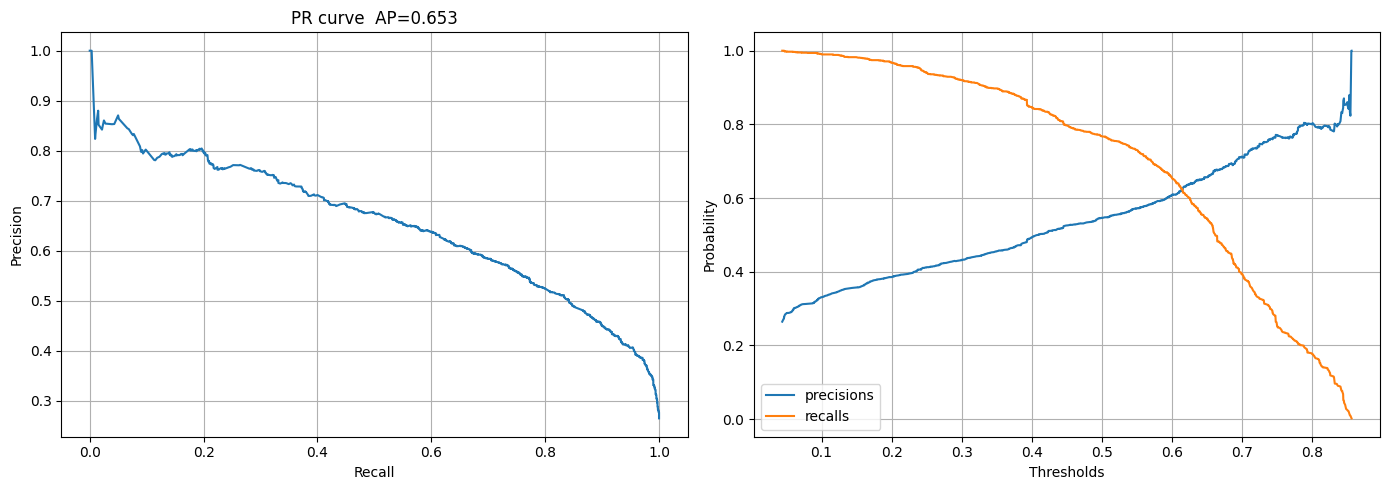

In [ ]:
y_pred = xgb_search.best_estimator_.predict(X_train)
y_score = xgb_search.best_estimator_.predict_proba(X_train)[:,1]
y_high_recall = [1 if s >= 0.2 else 0 for s in y_score]
print(classification_report(y_train,y_pred))
print(classification_report(y_train,y_high_recall))
print(confusion_matrix(y_train,y_pred))
print(confusion_matrix(y_train,y_high_recall))
pr_curve(xgb_search.best_estimator_)

              precision    recall  f1-score   support

           0       0.91      0.71      0.80      4131
           1       0.50      0.80      0.62      1485

    accuracy                           0.74      5616
   macro avg       0.71      0.76      0.71      5616
weighted avg       0.80      0.74      0.75      5616

              precision    recall  f1-score   support

           0       0.85      0.86      0.86      4131
           1       0.60      0.58      0.59      1485

    accuracy                           0.79      5616
   macro avg       0.73      0.72      0.72      5616
weighted avg       0.79      0.79      0.79      5616

[[2945 1186]
 [ 291 1194]]
[[3556  575]
 [ 620  865]]


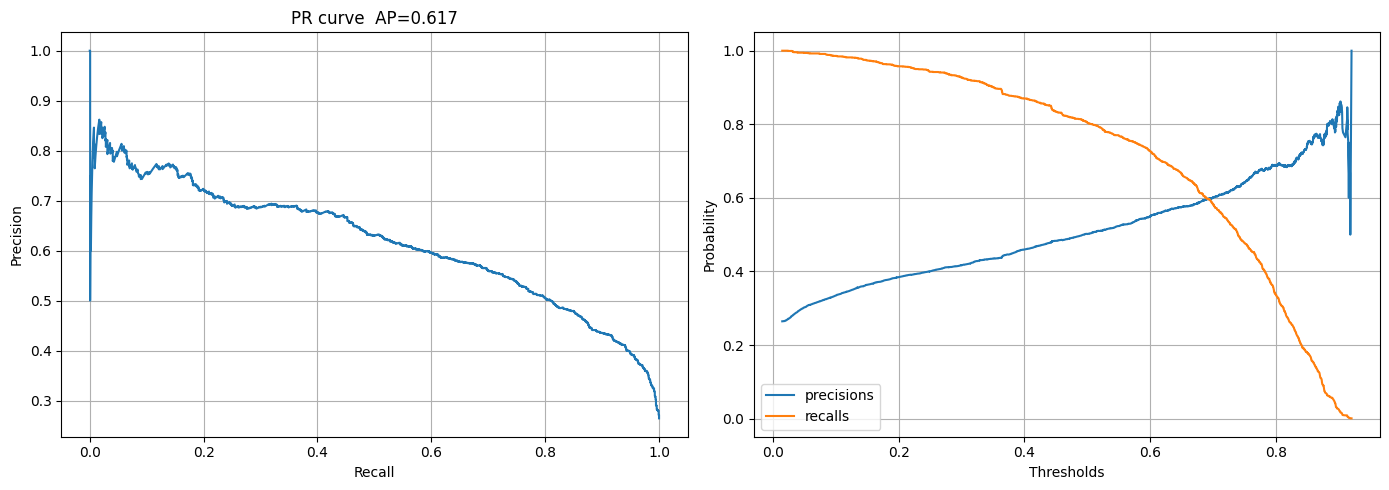

In [ ]:
y_pred = lr_search.best_estimator_.predict(X_train)
y_score = lr_search.best_estimator_.predict_proba(X_train)[:,1]
y_high_recall = [1 if s >= 0.7 else 0 for s in y_score]
print(classification_report(y_train,y_pred))
print(classification_report(y_train,y_high_recall))
print(confusion_matrix(y_train,y_pred))
print(confusion_matrix(y_train,y_high_recall))
pr_curve(lr_search.best_estimator_)

              precision    recall  f1-score   support

           0       0.92      0.78      0.84      4131
           1       0.57      0.81      0.67      1485

    accuracy                           0.79      5616
   macro avg       0.74      0.80      0.76      5616
weighted avg       0.83      0.79      0.80      5616

              precision    recall  f1-score   support

           0       0.98      0.58      0.72      4131
           1       0.45      0.96      0.61      1485

    accuracy                           0.68      5616
   macro avg       0.71      0.77      0.67      5616
weighted avg       0.84      0.68      0.69      5616

[[3209  922]
 [ 276 1209]]
[[2378 1753]
 [  60 1425]]


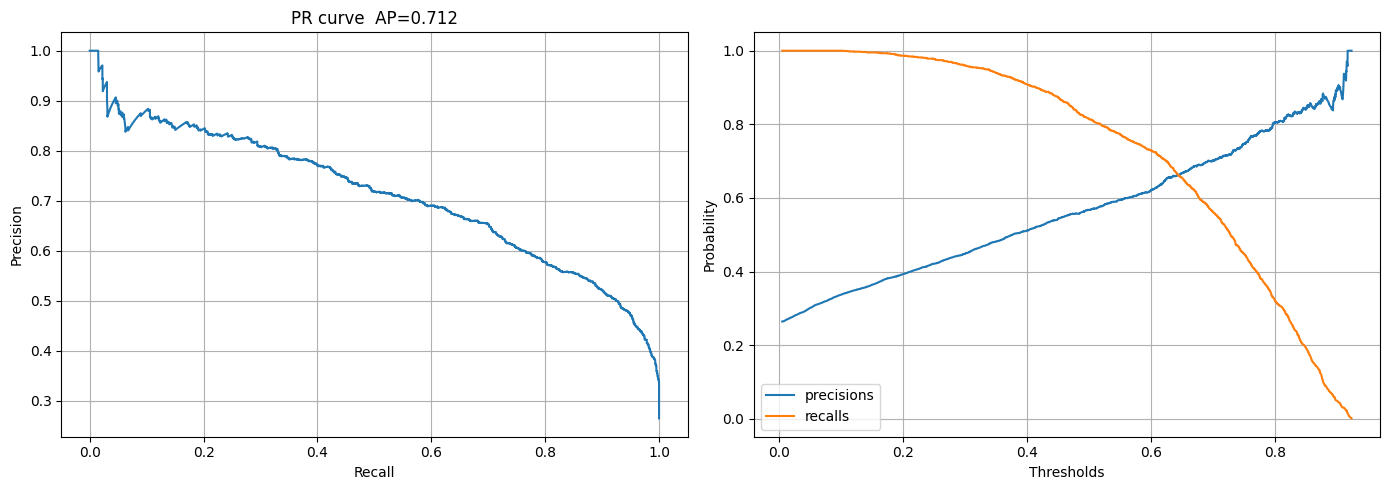

In [ ]:
y_pred = rf_search.best_estimator_.predict(X_train)
y_score = rf_search.best_estimator_.predict_proba(X_train)[:,1]
y_high_recall = [1 if s >= 0.3 else 0 for s in y_score]
print(classification_report(y_train,y_pred))
print(classification_report(y_train,y_high_recall))
print(confusion_matrix(y_train,y_pred))
print(confusion_matrix(y_train,y_high_recall))
pr_curve(rf_search.best_estimator_)

<!--  -->

### Creating a model with 0.90 Recall

In [ ]:
model_df

,model,precision_train,precision_test,recall_train,recall_test,accuracy_train,cross_val_accuracy,accuracy_test,f1_score_train,f1_score_test,cross_val_f1,roc_auc_score_train,cross_val_roc_auc,roc_auc_score_test,pr_auc_train,cross_val_pr_auc,pr_auc_test
0,LogisticRegression,0.502101,0.499142,0.804714,0.782258,0.737358,0.735754,0.734520,0.618370,0.609424,0.616999,0.758929,0.833452,0.749793,0.617313,0.617222,0.612109
1,SVC,0.620668,0.575198,0.675421,0.586022,0.805021,0.779913,0.775801,0.646888,0.580559,0.593536,0.763515,0.817343,0.715082,0.634721,0.573892,0.546051
2,DecisionTree,0.543972,0.530120,0.741414,0.709677,0.767272,0.754091,0.756584,0.627529,0.606897,0.618472,0.758991,0.829289,0.741576,0.597291,0.593047,0.584763
3,RandomForest,0.505453,0.502591,0.811448,0.782258,0.740207,0.735574,0.737367,0.622900,0.611987,0.613729,0.763022,0.834544,0.751729,0.635592,0.629650,0.625477
4,KNN,0.666954,0.583916,0.520539,0.448925,0.804487,0.770475,0.769395,0.584720,0.507599,0.522588,0.713549,0.799159,0.666863,0.642530,0.549537,0.532961
5,NaiveBayes,0.453671,0.448127,0.857239,0.836022,0.689281,0.688388,0.683986,0.593335,0.583490,0.591752,0.743071,0.812981,0.732628,0.588640,0.590462,0.567716
6,XGBoost,0.516432,0.518453,0.814815,0.793011,0.749288,0.740738,0.750178,0.632184,0.626993,0.618919,0.770274,0.841550,0.763882,0.648586,0.640182,0.639200
7,LogisticRegression_tuning,0.501681,0.499142,0.804040,0.782258,0.737001,0.736466,0.734520,0.617853,0.609424,0.618026,0.758471,0.833451,0.749793,0.617272,0.617544,0.611823
8,Randomforest_tuning,0.567339,0.534517,0.814141,0.728495,0.786681,0.764243,0.760142,0.668695,0.616610,0.631827,0.795475,0.837236,0.750017,0.711656,0.633080,0.625428
9,XGBoost_tuning,0.546021,0.536346,0.767003,0.733871,0.769765,0.764242,0.761566,0.637917,0.619750,0.630906,0.768881,0.842884,0.752705,0.653219,0.643718,0.638811


In [ ]:
# final_model is Hypertunes random forest
final_model = rf_search.best_estimator_.named_steps['randomforestclassifier']

In [ ]:
pipelines=[xgb_search,lr_search,rf_search]

for pipeline in pipelines:
  y_pred = pipeline.predict(X_train)
  y_score = pipeline.predict_proba(X_train)[:,1]
  precisions, recalls, thresholds = precision_recall_curve(y_train, y_score)
  id_90_recall = np.argmax(np.sort(recalls) >= 0.90)
  print(f"{pipeline.best_estimator_.steps[1][0]} Value for 90 recall : recall = {recalls[id_90_recall]:.3f}, precision = {precisions[id_90_recall]:.3f}, threshold = {thresholds[id_90_recall]:.3f}")


xgbclassifier Value for 90 recall : recall = 0.884, precision = 0.465, threshold = 0.371
logisticregression Value for 90 recall : recall = 0.823, precision = 0.488, threshold = 0.466
randomforestclassifier Value for 90 recall : recall = 0.954, precision = 0.462, threshold = 0.319


In [ ]:

for pipeline in pipelines:
  y_pred = pipeline.predict(X_train)
  y_score = pipeline.predict_proba(X_train)[:,1]
  precisions, recalls, thresholds = precision_recall_curve(y_train, y_score)

  id_90_precision = np.argmax(precisions[:-1] >= 0.85)
  print(f"{pipeline.best_estimator_.steps[1][0]} Value for 90 precision : recall = {recalls[id_90_precision]:.3f}, precision = {precisions[id_90_precision]:.3f}, threshold = {thresholds[id_90_precision]:.3f}")

xgbclassifier Value for 90 precision : recall = 0.051, precision = 0.864, threshold = 0.844
logisticregression Value for 90 precision : recall = 0.020, precision = 0.857, threshold = 0.901
randomforestclassifier Value for 90 precision : recall = 0.188, precision = 0.851, threshold = 0.852


In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import recall_score, precision_score
import numpy as np
from sklearn.base import clone


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=43)
recalls = []
precisions = []

base_pipeline = lr_search.best_estimator_

# Your tuned Random Forest parameters here
# model = RandomForestClassifier(random_state=42)
for train_idx, val_idx in skf.split(X_train, y_train):
    # Change X to X_train and y to y_train so the indices match correctly!
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    fold_model = clone(base_pipeline)
    fold_model.fit(X_tr, y_tr)
    preds = fold_model.predict(X_val)

    recalls.append(recall_score(y_val, preds))
    precisions.append(precision_score(y_val, preds))

print(f"Average CV Recall: {np.mean(recalls):.2%}")
print(f"Average CV Precision: {np.mean(precisions):.2%}")


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l1)
  warnings.warn(


Average CV Recall: 80.47%
Average CV Precision: 50.11%
